# Homicide Clearance Prediction in the United States

**Research question:** Can homicide incident characteristics, victim information, geographic factors, and other information available at the intended prediction time help predict whether a homicide case will be cleared or remain uncleared?

## Notebook purpose

This notebook evaluates the feasibility of using the 2023 National Incident-Based Reporting System (NIBRS) incident-level file as the project's primary modeling dataset. It covers extraction, initial validation, variable selection, missing-value investigation, and preliminary target investigation. Modeling has not started.

NIBRS is Layer 1 of the project's three-layer design. The Phoenix Homicide Clearance Initiative and MAP amplified Supplementary Homicide Reports will be examined separately in future notebooks. See [`../DATA_SOURCES.md`](../DATA_SOURCES.md) for complete source documentation.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("pandas: ", pd.__version__)
print("numpy: ", np.__version__)

pandas:  3.0.6
numpy:  2.5.3


In [2]:
# We want to see - Is V20061 actually available in the incident-level TSV?

file_path = "../data/raw/39270-0003-Data.tsv"

sample = pd.read_csv(file_path, sep="\t", nrows=5)

"V20061" in sample.columns

True

## 1. Confirm the homicide offense field

The sample confirms that `V20061` is present in the incident-level file. According to the codebook, `V20061` is **UCR Offense Code - 1**, and code `91` represents **Murder and Nonnegligent Manslaughter**.

A separate check confirmed that code `91` does not occur in `V20062` or `V20063` in this source file, so the current extraction uses `V20061 == 91`.

In [3]:
sample

,SEGMENT,STATE,FIPS_STATE,ORI,INCNUM,INCDATE,RECSBH,RECSADM,RECSOFS,RECSPRP,...,V60171,V60172,V60173,V60181,V60182,V60183,V60191,V60192,V60193,ALLOFNS
0,1,50,2,AK0010200,23000003,01-JAN-2023,1,1,1,1,...,,,,,,,,,,234
1,1,50,2,AK0010200,23000005,01-JAN-2023,1,1,1,0,...,,,,,,,,,,132
2,1,50,2,AK0010200,23000011,02-JAN-2023,1,1,1,1,...,,,,,,,,,,233
3,1,50,2,AK0010200,23000013,02-JAN-2023,1,1,1,0,...,,,,,,,,,,133
4,1,50,2,AK0010200,23000014,02-JAN-2023,1,1,2,1,...,,,,,,,,,,131 290


In [4]:
sample["V20061"]

0    234
1    132
2    233
3    133
4    131
Name: V20061, dtype: int64

In [5]:
sample[["INCNUM", "V20061"]]

,INCNUM,V20061
0,23000003,234
1,23000005,132
2,23000011,233
3,23000013,133
4,23000014,131


## 2. Extract homicide incidents from the source file

The source TSV is approximately 11 GB, so loading the entire file into memory at once is impractical. The extraction reads 100,000 rows at a time and retains rows where `V20061 == 91`.

`chunks = pd.read_csv(
    file_path,
    sep="\t",
    chunksize=100_000
)`

Get the first chunk
`first_chunk = next(chunks)`

`first_chunk.shape`
Output: (100000, 391)

Filter the first chunk
`homicide_chunk1 = first_chunk[first_chunk["V20061"] == 91]`

`homicide_chunk1.shape`
Output: (267, 391)

Total dataset: Approximately 12.35 million rows
Chunk size: 100,000 rows
12,350,000/ 100,000 = 123.5
Round up because the final chunk still contains data, total would be 124 chunks.
I want to use for loop instead of manually calling 'next(chunks)` for 124 times.

In [7]:
homicide_chunks = []

for chunk in pd.read_csv(file_path, sep="\t", chunksize=100_000):
    homicide_rows = chunk[chunk["V20061"] == 91]

    if not homicide_rows.empty:
        homicide_chunks.append(homicide_rows)

print("Non-empty chunks: ", len(homicide_chunks))
print("Totla homicides: ", sum(len(df) for df in homicide_chunks))

/var/folders/xg/_87j5pgx7_bfwvx0sj3y7r6m0000gn/T/ipykernel_35291/520244662.py:3: DtypeWarning: Columns (4: INCNUM, 32: BH024, 33: BH025, 62: BH054, 63: BH055, 222: V40171, 231: V4017C1, 232: V4017C2, 233: V4017C3, 351: V60071, 352: V60072, 353: V60073) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, sep="\t", chunksize=100_000):
/var/folders/xg/_87j5pgx7_bfwvx0sj3y7r6m0000gn/T/ipykernel_35291/520244662.py:3: DtypeWarning: Columns (22: BH014, 32: BH024, 33: BH025, 36: BH028, 37: BH029, 63: BH055, 64: BH056, 222: V40171, 231: V4017C1, 232: V4017C2, 353: V60073) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, sep="\t", chunksize=100_000):
/var/folders/xg/_87j5pgx7_bfwvx0sj3y7r6m0000gn/T/ipykernel_35291/520244662.py:3: DtypeWarning: Columns (4: INCNUM, 62: BH054, 222: V40171, 231: V4017C1, 232: V4017C2, 233: V4017C3, 336: V50071, 339: V50081, 342: V50091, 351: V60

Non-empty chunks:  124
Totla homicides:  14860


/var/folders/xg/_87j5pgx7_bfwvx0sj3y7r6m0000gn/T/ipykernel_35291/520244662.py:3: DtypeWarning: Columns (4: INCNUM, 22: BH014, 62: BH054, 222: V40171, 231: V4017C1, 336: V50071, 339: V50081, 342: V50091, 351: V60071, 352: V60072, 353: V60073) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(file_path, sep="\t", chunksize=100_000):


In [9]:
# Now turn the homicide__chunks Python list into one DataFrame
homicide_df = pd.concat(
    homicide_chunks,
    ignore_index=True
)

print("Shape: ", homicide_df.shape)
print("Offense codes: ", homicide_df["V20061"].unique())

Shape:  (14860, 391)
Offense codes:  [91]


### 2.1 Save the derived homicide dataset

The extraction produced 14,860 homicide incidents from approximately 12.35 million NIBRS incident records. The derived dataset is saved locally as `data/processed/nibrs_2023_homicides.csv`.

In [13]:
from pathlib import Path
output_path = Path("../data/processed/nibrs_2023_homicides.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
homicide_df.to_csv(output_path, index=False)

# Verify our file exist
print("file exist: ", output_path.exists())
print("File Size (MB): ", round(output_path.stat().st_size / 1024**2, 2))
# KiB   1024 ** 1
# MiB   1024 ** 2
# GiB   1024 ** 3
# TiB   1024 ** 4



file exist:  True
File Size (MB):  12.78


## 3. Load and validate the derived dataset

This stage checks the dataset shape, sample records, data types, and column variability before detailed cleaning begins.

In [ ]:
import pandas as pd
# load and inspect our homicide dataset
df = pd.read_csv("../data/processed/nibrs_2023_homicides.csv")

print(df.shape)
display(df.head())
df.info()

(14860, 391)


/var/folders/xg/_87j5pgx7_bfwvx0sj3y7r6m0000gn/T/ipykernel_35291/896078438.py:2: DtypeWarning: Columns (25: BH017, 231: V4017C1, 232: V4017C2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/nibrs_2023_homicides.csv")


,SEGMENT,STATE,FIPS_STATE,ORI,INCNUM,INCDATE,RECSBH,RECSADM,RECSOFS,RECSPRP,...,V60171,V60172,V60173,V60181,V60182,V60183,V60191,V60192,V60193,ALLOFNS
0,1,50,2,AK0010200,23001363,09-APR-2023,1,1,1,0,...,,,,,,,,,,91
1,1,50,2,AK0010200,23001511,23-APR-2023,1,1,1,0,...,0,,,1,,,,,,91
2,1,50,2,AK0010200,23001815,10-MAR-2023,1,1,1,0,...,,,,,,,,,,91
3,1,50,2,AK0010300,202307060076,06-JUL-2023,1,1,1,0,...,0,,,,,,,,,91
4,1,50,2,AK0011600,23-003432,14-JUN-2023,1,1,1,0,...,0,0,,1,1,,,,,91


<class 'pandas.DataFrame'>
RangeIndex: 14860 entries, 0 to 14859
Columns: 391 entries, SEGMENT to ALLOFNS
dtypes: int64(62), object(3), str(326)
memory usage: 44.3+ MB


### 3.1 Identify constant columns

A constant column contains the same value in every row. It cannot distinguish between outcomes within this extracted dataset, although it may still document how the file was constructed.

In [ ]:
# explore a column - what content under the SEGMENT column
df["SEGMENT"].value_counts(dropna=False)

SEGMENT
1    14860
Name: count, dtype: int64

All 14,860 extracted incidents have the same `SEGMENT` value. Therefore, `SEGMENT` cannot help distinguish cleared from uncleared incidents within this dataset.

The next check identifies whether any other columns are constant.

In [18]:
unique_counts = df.nunique(dropna=False)

constant_columns = unique_counts[unique_counts == 1]

print(constant_columns)
print("Number of constant columns: ", len(constant_columns))

SEGMENT    1
RECSBH     1
RECSADM    1
BH005      1
BH014      1
          ..
V40252     1
V40253     1
V40293     1
V40302     1
V40303     1
Length: 66, dtype: int64
Number of constant columns:  66


/var/folders/xg/_87j5pgx7_bfwvx0sj3y7r6m0000gn/T/ipykernel_35291/1919097223.py:13: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


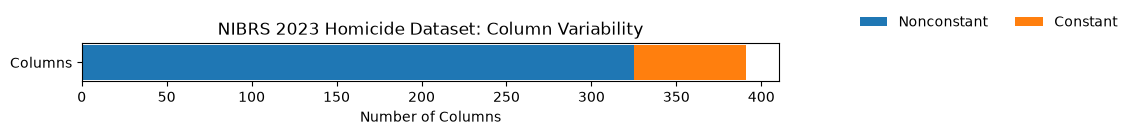

In [32]:
total_columns = df.shape[1]
constant_count = len(constant_columns)
nonconstant_count = total_columns - constant_count

plt.figure(figsize=(9, 0.5))

plt.barh("Columns", nonconstant_count, label="Nonconstant")
plt.barh("Columns", constant_count, left=nonconstant_count, label="Constant")

plt.xlabel("Number of Columns")
plt.title("NIBRS 2023 Homicide Dataset: Column Variability")
plt.legend(loc="lower center", bbox_to_anchor=(1.3, 1.02), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

### 3.2 First-pass missing-value check

The initial pandas check only detects recognized null values. A result of zero does not prove that the dataset is complete because this source also uses blank strings and special numeric codes.

In [34]:
missing_counts = df.isna().sum()

missing_percentage = (missing_counts / len(df)) * 100

print(missing_percentage.sort_values(ascending=False).head(10))

SEGMENT    0.0
V40213     0.0
V40291     0.0
V40283     0.0
V40282     0.0
V40281     0.0
V40273     0.0
V40272     0.0
V40271     0.0
V40263     0.0
dtype: float64


## 4. Select variables for investigation

Reviewing all 391 columns at once would make the early analysis difficult to interpret. The following 41 variables were selected from the codebook for initial data-quality and target investigation. This is a provisional investigation set, not the final model feature set.

Two questions remain for later stages:

1. Which variables are suitable predictors?
2. Which variables reveal the outcome or become available only after the intended prediction time?

In [119]:
selected_columns = [
    "ORI", "STATE", "INCNUM", "INCDATE", "FIPS_STATE", 
    "RECSVIC", "RECSOFR", "RECSOFS", "RECSARR", "BH007",
    "BH008", "BH019", "BH009", "BH040",
    "BH042", "BH043", "BH044", "BH045", "BH046", "BH047",
    "BH048", "BH049", "BH050", "BH051", "BH052", "BH053",
    "V1006", "V1007", "V1013", "V1014", "V20111", "V20061", "V20171",
    "V20081", "V20201", "V30071", "V40181", "V40191",
    "V40201", "V40211", "V40221"
]

Selected columns: 
| # | Variable | Description |
|---|---|---|
| 1 | `ORI` | Originating Agency Identifier |
| 2 | `STATE` | Numeric State Code |
| 3 | `INCNUM` | Incident Number |
| 4 | `INCDATE` | Incident Date |
| 5 | `RECSVIC` | N Victim (04) Records per ORI-Incident Number |
| 6 | `RECSOFR` | N Offender (05) Records per ORI-Incident Number |
| 7 | `RECSARR` | N Arrestee (06) Records per ORI-Incident Number |
| 8 | `BH008` | State Abbreviation |
| 9 | `BH019` | Current Population 1 |
| 10 | `BH009` | Population Group |
| 11 | `BH040` | Number of Months Reported |
| 12 | `BH042` | Agency Activity Indicators January |
| 13 | `BH043` | Agency Activity Indicators February |
| 14 | `BH044` | Agency Activity Indicators March |
| 15 | `BH045` | Agency Activity Indicators April |
| 16 | `BH046` | Agency Activity Indicators May |
| 17 | `BH047` | Agency Activity Indicators June |
| 18 | `BH048` | Agency Activity Indicators July |
| 19 | `BH049` | Agency Activity Indicators August |
| 20 | `BH050` | Agency Activity Indicators September |
| 21 | `BH051` | Agency Activity Indicators October |
| 22 | `BH052` | Agency Activity Indicators November |
| 23 | `BH053` | Agency Activity Indicators December |
| 24 | `V1007` | Incident Date Hour |
| 25 | `V1013` | Cleared Exceptionally |
| 26 | `V1014` | Exceptional Clearance Date |
| 27 | `V20111` | Location Type - 1 |
| 28 | `V20171` | Weapon / Force 1 - 1 |
| 29 | `V20081` | Offender(s) Suspected of Using 1 - 1 |
| 30 | `V20201` | Bias Motivation 1 - 1 |
| 31 | `V30071` | Property Description - 1 |
| 32 | `V40181` | Age of Victim - 1 |
| 33 | `V40191` | Sex of Victim - 1 |
| 34 | `V40201` | Race of Victim - 1 |
| 35 | `V40211` | Ethnicity of Victim - 1 |
| 36 | `V40221` | Resident Status of Victim - 1 |
| 37 | `V20061` | UCR Offense Code - 1 |
| 38 | `BH007` | City Name |
| 39 | `FIPS_STATE` | FIPS State Numeric Code |
| 40 | `RECSOFS` | N Offense (02) Records per ORI-Incident Number |
| 41 | `V1006` | Report Date Indicator |

In [120]:
missing_columns = [col for col in selected_columns if col not in df.columns]

print("Selected: ", len(selected_columns))
print("Not found: ", missing_columns)


Selected:  41
Not found:  []


In [121]:
# Create a smaller working dataframe
homicide_selected_df = df[selected_columns].copy()
print(homicide_selected_df.shape)
homicide_selected_df.dtypes

(14860, 41)


ORI             str
STATE         int64
INCNUM          str
INCDATE         str
FIPS_STATE    int64
RECSVIC       int64
RECSOFR       int64
RECSOFS       int64
RECSARR       int64
BH007           str
BH008           str
BH019         int64
BH009         int64
BH040         int64
BH042         int64
BH043         int64
BH044         int64
BH045         int64
BH046         int64
BH047         int64
BH048         int64
BH049         int64
BH050         int64
BH051         int64
BH052         int64
BH053         int64
V1006         int64
V1007         int64
V1013           str
V1014           str
V20111        int64
V20061        int64
V20171        int64
V20081          str
V20201        int64
V30071          str
V40181          str
V40191          str
V40201          str
V40211          str
V40221          str
dtype: object

## 5. Investigate missing and special values

According to the codebook, missing or unknown values are represented in different ways, including recognized nulls, blank strings, punctuation, and negative codes. Their meanings can vary by variable, so they should not all be replaced automatically.
| Columns | Missing/unknown codes documented |
|---|---|
| `ORI`, `STATE`, `INCNUM`, `INCDATE` | No explicit missing codes listed |
| `RECSVIC`, `RECSOFR`, `RECSARR`, `RECSOFS` | `-5` |
| `BH007`, `BH008`, `BH019` | No explicit missing codes listed |
| `BH009`, `BH040` | `.` |
| `BH042`–`BH053` | `.` |
| `FIPS_STATE` | No explicit missing codes listed |
| `V1006` | `-5` |
| `V1007` | `-7`, `-5` |
| `V1013` | `.`, `-6`, `-5` |
| `V1014` | Blank date entries |
| `V20061` | `-9` through `-5` |
| `V20081` | `.`, `-9` through `-5` |
| `V20111`, `V20201` | `-9` through `-5` |
| `V20171`, `V30071` | `.`, `-9` through `-5` |
| `V40181` | `.` |
| `V40191` | `.`, `-9`, `-7`, `-6` |
| `V40201`, `V40211`, `V40221` | `.`, `-9` through `-5` |

The following checks compare standard null counts with blank strings and documented special codes.

Final decisions about exclusion, preservation, or imputation will be made only after each variable's meaning and missing-value mechanism are understood.

In [122]:
# Check missing values in the homicide_selected_df 
missing_count = homicide_selected_df.isna().sum()

missing_percentage = (homicide_selected_df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({"Missing Count": missing_count, "Missing %": missing_percentage})

display(missing_summary.sort_values("Missing %", ascending=False).head(15))


,Missing Count,Missing %
ORI,0,0.0
BH049,0,0.0
BH051,0,0.0
BH052,0,0.0
BH053,0,0.0
V1006,0,0.0
V1007,0,0.0
V1013,0,0.0
V1014,0,0.0
V20111,0,0.0


In [123]:
homicide_selected_df.head(10)

,ORI,STATE,INCNUM,INCDATE,FIPS_STATE,RECSVIC,RECSOFR,RECSOFS,RECSARR,BH007,...,V20061,V20171,V20081,V20201,V30071,V40181,V40191,V40201,V40211,V40221
0,AK0010200,50,23001363,09-APR-2023,2,1,1,1,0,FAIRBANKS,...,91,120,,88,,35,1,3,0,0
1,AK0010200,50,23001511,23-APR-2023,2,1,1,1,1,FAIRBANKS,...,91,400,1,88,,25,0,3,0,1
2,AK0010200,50,23001815,10-MAR-2023,2,2,1,1,0,FAIRBANKS,...,91,120,,88,,64,0,1,0,1
3,AK0010300,50,202307060076,06-JUL-2023,2,1,1,1,1,JUNEAU,...,91,110,,88,,23,1,1,0,
4,AK0011600,50,23-003432,14-JUN-2023,2,1,2,1,2,KOTZEBUE,...,91,200,1,88,,33,1,3,0,1
5,AK0011800,50,23000717,26-NOV-2023,2,1,1,1,0,BARROW,...,91,130,1,88,,29,1,5,0,1
6,AK0012300,50,2302-0173,12-FEB-2023,2,1,1,1,1,KENAI,...,91,400,3,88,,33,0,1,,
7,AK0012500,50,324395,22-APR-2023,2,3,1,1,0,METLAKATLA,...,91,350,1,88,,25,1,3,0,0
8,AKAST0100,50,AK23006543,20-JAN-2023,2,3,1,3,1,Anchorage,...,91,120,,88,,44,1,1,,1
9,AKAST0100,50,AK23013544,08-FEB-2023,2,2,1,2,0,Anchorage,...,91,120,1,88,,41,1,3,,1


In [124]:
# Random select the column V20081 to see what are the values
print(homicide_selected_df["V20081"].value_counts(dropna=False))
print(homicide_selected_df["V20081"].unique())

V20081
     13759
1      607
3      462
2       32
Name: count, dtype: int64
<StringArray>
[' ', '1', '3', '2']
Length: 4, dtype: str


### 5.1 Blank-string example: `V20081`

The column `V20081` (Offender(s) Suspected of Using 1 - 1) uses whitespace for many unrecorded entries. The output shows 13,759 blank cells, or approximately 92.6% of incidents. This does not yet determine whether the column should be removed; its meaning and missingness will be considered during feature selection.

In [125]:
# Count missing values entries in each column, ZERO != missing values
blank_counts = homicide_selected_df.apply(
    lambda col: (
        col.astype("string").str.fullmatch(r"\s*").fillna(False)
        | pd.to_numeric(col, errors="coerce").between(-9, -5)
    ).sum()
)

blank_summary = pd.DataFrame({
    "Blank Count": blank_counts,
    "Blank %": (blank_counts / len(homicide_selected_df) * 100).round(2)
})

display(blank_summary.sort_values("Blank %", ascending=False).head(13))

,Blank Count,Blank %
V1013,14265,96.00
V1014,14265,96.00
V20081,13759,92.59
V30071,13645,91.82
V40221,4528,30.47
V40211,3356,22.58
V40201,648,4.36
V20171,607,4.08
V40181,339,2.28
V40191,257,1.73


### 5.2 Manually inspect variables without explicit missing codes

The codebook does not list explicit missing codes for the following variables, so their observed values are reviewed directly:

- `ORI`, `STATE`, `INCNUM`, and `INCDATE`
- `BH007`, `BH008`, and `BH019`
- `FIPS_STATE`

In [130]:
manual_check = ["ORI", "STATE", "INCNUM", "INCDATE", "BH007", "BH008", "BH019", "FIPS_STATE"]

for col in manual_check:
    print(f"\n--- {col} ---")
    print(homicide_selected_df[col].unique())


--- ORI ---
<StringArray>
['AK0010200', 'AK0010300', 'AK0011600', 'AK0011800', 'AK0012300', 'AK0012500',
 'AKAST0100', 'AL0010000', 'AL0010100', 'AL0010200',
 ...
 'WY0070200', 'WY0110100', 'WY0110400', 'WY0120000', 'WY0130100', 'WY0150000',
 'WY0150100', 'WY0170100', 'WY0190000', 'WYDI05000']
Length: 2939, dtype: str

--- STATE ---
[50  1  3  2  4  5  6  8  7  9 10 55 51 14 11 12 13 15 16 17 20 19 18 21
 22 24 23 25 26 32 33 28 29 30 27 31 34 35 36 37 38 39 40 41 42 43 45 44
 46 48 47 49]

--- INCNUM ---
<StringArray>
[    '23001363',     '23001511',     '23001815', '202307060076',
    '23-003432',     '23000717',    '2302-0173',       '324395',
   'AK23006543',   'AK23013544',
 ...
      '2300135',    '23-001421',    '23-027899',       '23-739',
      '23-1044',    '23P000127',    'S23-13077',       '329220',
       '329525',       '377428']
Length: 14816, dtype: str

--- INCDATE ---
<StringArray>
['09-APR-2023', '23-APR-2023', '10-MAR-2023', '06-JUL-2023', '14-JUN-2023',
 '26-NOV-2

## 6. Missing-city case study: `BH007`

`BH007` (City Name) has blank values in 0.77% of incidents. This case study tests whether those values can be recovered from the reporting agency identifier (`ORI`) without introducing unsupported information.

The first step checks whether each `ORI` maps consistently to one state and one known city.

In [135]:
ori_state_check = (
    homicide_selected_df
    .groupby("ORI")["STATE"]
    .nunique(dropna=False)
)

print("Total unique ORIs:", len(ori_state_check))
print("ORIs associated with multiple states:", (ori_state_check > 1).sum())

Total unique ORIs: 2939
ORIs associated with multiple states: 0


In [136]:
ori_city_check = (
    homicide_selected_df
    .assign(
        BH007=homicide_selected_df["BH007"].str.strip().replace("", pd.NA)
    )
    .groupby("ORI")["BH007"]
    .nunique()
)

print("Total unique ORIs:", len(ori_city_check))
print("ORIs associated with multiple cities:", (ori_city_check > 1).sum())
print("ORIs with no known city:", (ori_city_check == 0).sum())

Total unique ORIs: 2939
ORIs associated with multiple cities: 0
ORIs with no known city: 43


Each `ORI` with an observed city maps to exactly one city in this extracted dataset.

There are 115 records with blank city names and 43 ORIs with no known city.

The next check determines whether any blank records belong to an `ORI` that has a city recorded elsewhere in the dataset.

In [137]:
# ORIs that have at least one known city
oris_with_known_city = ori_city_check[ori_city_check == 1].index

# Records with blank city names
blank_city = (
    homicide_selected_df["BH007"].isna()
    | homicide_selected_df["BH007"].str.strip().eq("")
)

# Count blank records that can be matched to a known city
recoverable = (
    blank_city
    & homicide_selected_df["ORI"].isin(oris_with_known_city)
)

print("Total blank city records:", blank_city.sum())
print("Potentially recoverable:", recoverable.sum())
print("Cannot recover using ORI:", (blank_city & ~recoverable).sum())

Total blank city records: 115
Potentially recoverable: 0
Cannot recover using ORI: 115


### 6.1 Decision: retain missing city values
Out of 14,860 homicide records, 115 records (0.77%) have missing city names.

To investigate whether these values could be recovered, I examined the relationship between the reporting agency identifier (`ORI`) and city name (`BH007`).

Since the missing city names cannot be recovered from the existing records, I decided to leave them missing rather than introduce potentially inaccurate information.

Other geographic variables, such as `STATE` and `FIPS_STATE`, may still provide location information.

Whether `BH007` belongs in the final feature set will be revisited during feature selection.

## 7. Summarize observed special missing-value codes

This summary counts the negative special codes observed across the 41 selected variables. The codebook must still be consulted before assigning a cleaning action because the meaning of a code can differ by variable.

In [145]:
special_codes = ["-5", "-6", "-7", "-8", "-9"]

df_string = homicide_selected_df.astype("string")

special_code_summary = {}

for code in special_codes:
    special_code_summary[code] = df_string.apply(lambda col: col.str.strip().eq(code).sum())

special_code_summary = pd.DataFrame(special_code_summary)

display(special_code_summary[(special_code_summary != 0).any(axis=1)])

,-5,-6,-7,-8,-9
V20171,0,0,607,0,0
V40181,0,0,151,0,0
V40191,0,0,69,0,0
V40201,0,0,460,0,0
V40211,0,0,1281,0,0
V40221,0,0,1390,0,0


## 8. Investigate the prediction target

The research question requires a defensible definition of whether an incident was cleared or remained uncleared. The target has not yet been finalized.

At this stage, it is important to distinguish the target from the predictors:

| Type | Purpose | Example |
|---|---|---|
| Target (`y`) | The outcome to predict | Cleared or uncleared |
| Features (`X`) | Information used to make the prediction | Victim age, weapon, location, and incident characteristics |

Two variables are explored as possible outcome indicators:

- `RECSARR` — Number of Arrestee Records per Incident
- `V1013` — Exceptional Clearance Reason

Their relationship is examined with a contingency table. This investigation does not yet establish the final target definition.

In [146]:
print("RECSARR unique values:")
print(homicide_selected_df["RECSARR"].unique())

print("\nRECSARR distribution:")
display(
    homicide_selected_df["RECSARR"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Incident Count")
)

RECSARR unique values:
[ 0  1  2  3  6  5  4 10  8  7  9]

RECSARR distribution:


,Incident Count
RECSARR,
0,7807
1,5792
2,826
3,287
4,84
5,38
6,15
7,5
8,2


In [148]:
print("V1013 (Cleared Exceptionally) unique values:")
print(homicide_selected_df["V1013"].unique())

print("\nV1013 distribution:")
display(
    homicide_selected_df["V1013"]
    .value_counts(dropna=False)
    .to_frame("Incident Count")
)

V1013 (Cleared Exceptionally) unique values:
<StringArray>
[' ', '1', '5', '3', '2', '4']
Length: 6, dtype: str

V1013 distribution:


,Incident Count
V1013,
,14265
1,433
2,106
3,50
5,3
4,3


In [ ]:
# Contingency table / cross-tabulation
# Does the incident have at least one arrest record?
has_arrest = homicide_selected_df["RECSARR"] > 0

# Does the incident have an exceptional clearance reason?
has_exceptional = (
    homicide_selected_df["V1013"]
    .astype("string")
    .str.strip()
    .isin(["1", "2", "3", "4", "5"])
)

display(
    pd.crosstab(
        has_arrest,
        has_exceptional,
        rownames=["Has Arrest Record"],
        colnames=["Exceptional Clearance"]
    )
)

Exceptional Clearance,False,True
Has Arrest Record,,
False,7212,595
True,7053,0


### 8.1 Contingency-table findings

* **7,212**: No arrest record AND no exceptional clearance reason.

* **595**: No arrest record BUT the case was exceptionally cleared.

* **7,053**: At least one arrest record AND no exceptional clearance reason.

* **0**: At least one arrest record AND an exceptional clearance reason.

### 8.2 Preliminary interpretation

None of the 14,860 incidents has both an arrestee record and an exceptional-clearance reason. This pattern is consistent with exceptional clearance being used when an arrest cannot be made.

A possible target definition would classify the 7,053 incidents with an arrestee record and the 595 exceptionally cleared incidents as cleared. However, this remains a hypothesis until the reporting rules and timing are verified. The 7,212 incidents with neither indicator should not yet be labeled uncleared solely from this cross-tabulation.

## 9. Define the prediction time and review leakage — Future work

> **Status:** Not yet completed.

Before selecting model features, define when the prediction is intended to occur. Then document whether each candidate variable would be available at that time. Variables used to construct or reveal the outcome, including `RECSARR`, `V1013`, and `V1014`, must not also be used as predictors.

**Template to complete:**

- Intended prediction time:
- Information available at that time:
- Variables reserved for target construction:
- Variables excluded because of leakage:

## 10. Finalize cleaning and feature selection — Future work

> **Status:** Not yet completed.

**Template to complete:**

- Final target definition and justification:
- Variables retained as candidate features:
- Variables excluded and reasons:
- Missing-value treatment by variable:
- Categorical encoding plan:

## 11. Modeling and evaluation — Future work

> **Status:** Not yet started.

**Template to complete:**

- Train/test split strategy:
- Baseline model:
- Comparison model(s):
- Evaluation metrics:
- Error analysis:

## 12. Current checkpoint

Completed in this notebook:

- Extracted 14,860 NIBRS homicide incidents from the large source file.
- Performed initial structural and missing-value checks.
- Selected 41 variables for investigation.
- Documented the missing-city decision.
- Compared arrestee records with exceptional-clearance reasons.

Next decision: verify and document a defensible clearance target before feature selection or modeling.